# SmogWindow v2 — does ML improve a Lahore school's pollution *decision*?
**Veritas AI Hackathon 2026 · AI + Climate · Muhammad Fasih Ajmal (solo)**

Historical research prototype on **modeled (CAMS) data**; not live monitoring, medical advice or a safety clearance. **Run all** in Colab: the data and every script are embedded; no API key or download.

**Headline (walk-forward, out-of-sample):** forecast MAE vs "tomorrow = today": development 12.47→12.04 (3.4%), 2025 *known benchmark* 14.05→12.92 (8.1%), new Jan–Feb 2026 holdout 24.35→22.64 (7.0%). Against *equally calibrated persistence* the ML warning advantage is small and mostly within noise, so we do not claim it is better. Not done: ground-monitor validation, school review, live feed.

In [1]:
# 1. Restore the embedded, attributed public dataset (no network).
from pathlib import Path
import base64, io, zipfile, os
ROOT = Path.cwd() / "SmogWindow_notebook_run"; ROOT.mkdir(exist_ok=True)
DATA_ZIP_BASE64 = "..."
zipfile.ZipFile(io.BytesIO(base64.b64decode(DATA_ZIP_BASE64))).extractall(ROOT)
os.chdir(ROOT); print("data files:", sorted(p.name for p in (ROOT/"data").iterdir()))

data files: ['GROUND_DATA_GUIDE.md', 'README.md', 'air_quality_historical.csv', 'city_info.csv', 'data_dictionary.csv', 'dataset-metadata.json']


## 2. The code (written to disk so you can read each file)

In [2]:
%%writefile model.py
"""Small, auditable NumPy models. No network, API key or scikit-learn required."""
import numpy as np
import pandas as pd

POLLUTANTS = ['pm10','carbon_monoxide','nitrogen_dioxide','sulphur_dioxide','ozone','aerosol_optical_depth','dust','uv_index']

def features(raw):
    d = raw.copy().sort_index()
    assert not d.index.duplicated().any(), 'Duplicate dates'
    d = d.reindex(pd.date_range(d.index.min(), d.index.max(), freq='D'))
    p = d.pm2_5
    x = pd.DataFrame(index=d.index)
    for lag in [0,1,2,3,6,13]:
        x[f'pm_lag_{lag}'] = p.shift(lag)
    for w in [3,7,14]:
        x[f'pm_mean_{w}'] = p.rolling(w, min_periods=w).mean()
        x[f'pm_std_{w}'] = p.rolling(w, min_periods=w).std()
    x['pm_change'] = p-p.shift(1)
    # Tomorrow's calendar is known at prediction time.
    day=(x.index+pd.Timedelta(days=1)).dayofyear
    for k in [1,2]:
        x[f'season_sin_{k}']=np.sin(2*np.pi*k*day/365.25)
        x[f'season_cos_{k}']=np.cos(2*np.pi*k*day/365.25)
    history=list(x.columns)
    for col in POLLUTANTS:
        x[col]=d[col]
        x[col+'_lag1']=d[col].shift(1)
    return x, p.shift(-1).rename('target'), history

def fit_model(x, y, config):
    a=np.asarray(x,float); y=np.asarray(y,float)
    mu=a.mean(axis=0); sd=a.std(axis=0); sd[sd<1e-9]=1
    z=(a-mu)/sd
    base=a[:,0]  # today's PM2.5
    residual=(np.log1p(y)-np.log1p(base)) if config.get('log') else y-base
    model={'config':config,'columns':list(x.columns),'mean':mu.tolist(),'scale':sd.tolist()}
    if config['kind']=='ridge':
        design=np.column_stack([np.ones(len(z)),z])
        penalty=np.eye(design.shape[1])*config['alpha']; penalty[0,0]=0
        beta=np.linalg.solve(design.T@design+penalty,design.T@residual)
        model['beta']=beta.tolist()
    else:
        # Gradient boosting of depth-one regression trees, fitted to change from persistence.
        # Quantile thresholds are computed only on fitting data.
        masks=[]; cuts=[]
        for j in range(z.shape[1]):
            for cut in np.unique(np.quantile(z[:,j],np.linspace(.1,.9,9))):
                mask=z[:,j]<=cut
                if min(mask.sum(),(~mask).sum())>=15:
                    masks.append(mask); cuts.append((j,float(cut)))
        masks=np.asarray(masks,float); counts=masks.sum(axis=1)
        init=float(residual.mean()); pred=np.full(len(y),init); trees=[]
        for _ in range(config['steps']):
            err=residual-pred; sums=masks@err
            left=sums/counts; right=(err.sum()-sums)/(len(y)-counts)
            gain=sums*sums/counts+(err.sum()-sums)**2/(len(y)-counts)
            ix=int(gain.argmax()); j,cut=cuts[ix]
            l=float(left[ix])*.05; r=float(right[ix])*.05
            pred+=np.where(z[:,j]<=cut,l,r)
            trees.append([j,cut,l,r])
        model.update(intercept=init,trees=trees)
    return model

def predict(model, x):
    a=np.asarray(x[model['columns']],float)
    z=(a-np.array(model['mean']))/np.array(model['scale'])
    if model['config']['kind']=='ridge':
        delta=np.column_stack([np.ones(len(z)),z])@np.array(model['beta'])
    else:
        delta=np.full(len(z),model['intercept'])
        for j,cut,l,r in model['trees']:
            delta+=np.where(z[:,j]<=cut,l,r)
    if model['config'].get('log'):
        return np.maximum(0,np.expm1(np.log1p(a[:,0])+delta))
    return np.maximum(0,a[:,0]+delta)

def warning_metrics(y, score, threshold=55., ratio=3.):
    actual=np.asarray(y)>threshold; flag=np.asarray(score)>threshold
    tp=int((actual&flag).sum()); fn=int((actual&~flag).sum())
    fp=int((~actual&flag).sum()); tn=int((~actual&~flag).sum())
    return dict(tp=tp,fn=fn,fp=fp,tn=tn,recall=tp/(tp+fn) if tp+fn else None,
                precision=tp/(tp+fp) if tp+fp else None,flagged=int(flag.sum()),
                cost=float(ratio*fn+fp),threshold=float(threshold),ratio=float(ratio))


# ---------------------------------------------------------------- v2 additions
MINIMAL=['pm_lag_0','pm_mean_7','pm_change','season_sin_1','season_cos_1']

def columns_for(config, all_columns, history):
    """Feature columns a candidate may use: 'history' (PM2.5+calendar), 'minimal', or 'full'."""
    return {'history':list(history),'minimal':[c for c in MINIMAL if c in all_columns],'full':list(all_columns)}[config['features']]

def climatology(train_target_dates, train_y, query_dates, half_window=15):
    """Mean of training-period targets within +-half_window calendar days of each query date."""
    td=np.asarray(pd.DatetimeIndex(train_target_dates).dayofyear); ty=np.asarray(train_y,float)
    out=[]
    for q in pd.DatetimeIndex(query_dates).dayofyear:
        gap=np.abs(td-q); gap=np.minimum(gap,365-gap)
        m=gap<=half_window
        out.append(ty[m].mean() if m.any() else ty.mean())
    return np.array(out)

def data_quality(raw, origin, lookback=14):
    """Plain-language warnings for the 14-day window that feeds a forecast issued on `origin`.
    `raw` is a daily DataFrame indexed by date with a pm2_5 column."""
    origin=pd.Timestamp(origin)
    window=raw.reindex(pd.date_range(origin-pd.Timedelta(days=lookback-1),origin,freq='D')).pm2_5
    flags=[]
    missing=int(window.isna().sum())
    if missing: flags.append(f'{missing} of the last {lookback} days have no PM2.5 value; a forecast cannot be issued until the gap is filled.')
    if raw.index.max()<origin: flags.append('No data on or after the origin date; the forecast would be an extrapolation.')
    if window.notna().all() and window.iloc[-1]>raw.pm2_5.quantile(.99):
        flags.append('Today is above the 99th percentile of all history; forecasts for extreme days are least reliable.')
    return {'missing_days':missing,'complete':missing==0,'flags':flags}


Writing model.py


In [3]:
%%writefile evaluation.py
"""Walk-forward evaluation, uncertainty calibration schemes and scoring. NumPy/pandas only."""
import numpy as np
import pandas as pd
from model import features, fit_model, predict, columns_for, climatology, warning_metrics

RATIOS = (1, 3, 5)
THRESHOLDS = (35, 55, 100)
PRIMARY = (55., 3.)  # fixed before any evaluation; illustrative, not a regulation
SEASONS = {'Winter': [12, 1, 2], 'Spring': [3, 4, 5], 'Summer': [6, 7, 8], 'Autumn': [9, 10, 11]}

# Every candidate is scored on identical rows. 'baseline' entries use no fitted parameters.
SPECS = {
    'Persistence':            {'kind': 'persistence'},
    'Trailing 7-day mean':    {'kind': 'mean7'},
    'Seasonal climatology':   {'kind': 'climatology'},
    'Persistence+climate 50/50': {'kind': 'blend'},
    'Ridge minimal (a=100)':  {'kind': 'ridge', 'alpha': 100, 'features': 'minimal'},
    'Ridge history (a=100)':  {'kind': 'ridge', 'alpha': 100, 'features': 'history'},
    'Ridge history (a=1000)': {'kind': 'ridge', 'alpha': 1000, 'features': 'history'},
    'Log-ridge history (a=100)':  {'kind': 'ridge', 'alpha': 100, 'features': 'history', 'log': True},
    'Log-ridge history (a=1000)': {'kind': 'ridge', 'alpha': 1000, 'features': 'history', 'log': True},
    'Ridge full (a=1000)':    {'kind': 'ridge', 'alpha': 1000, 'features': 'full'},
    'Boosted stumps (150)':   {'kind': 'stumps', 'steps': 150, 'features': 'full'},
}
BASELINES = [k for k, v in SPECS.items() if v['kind'] in ('persistence', 'mean7', 'climatology', 'blend')]
FITTED = [k for k in SPECS if k not in BASELINES]
SCHEMES = ['global_abs', 'global_signed', 'trail90', 'trail180', 'level_bins', 'log_relative']
SCHEME_LABEL = {'global_abs': 'All-past |error| (v1 style)', 'global_signed': 'All-past signed errors',
                'trail90': 'Trailing 90 days', 'trail180': 'Trailing 180 days',
                'level_bins': 'By forecast level (terciles)', 'log_relative': 'Relative (log-scale) errors'}


def load_series(path):
    raw = pd.read_csv(path, parse_dates=['date']).set_index('date').sort_index()
    assert raw.index.is_unique
    assert (raw.select_dtypes('number').dropna() >= 0).all().all()
    # The first non-null day looks like a partial day of averaging; excluded conservatively (inference).
    raw.loc[pd.Timestamp('2022-08-04'), :] = np.nan
    return raw


def build_frame(raw):
    x, y, history = features(raw)
    good = x.notna().all(axis=1) & y.notna()
    x = x.loc[good]; y = y.loc[good]
    tdates = x.index + pd.Timedelta(days=1)
    return x, y, history, pd.DatetimeIndex(tdates)


def walk_forward(x, y, tdates, history, first, last, specs=SPECS):
    """Operational simulation. Models are refit at the start of each month using only rows whose target
    date is before that month. Nothing dated on/after the forecast's origin informs its model."""
    sel = np.where((tdates >= first) & (tdates <= last))[0]
    months = pd.PeriodIndex(tdates[sel], freq='M')
    out = pd.DataFrame({'origin_date': x.index[sel], 'actual': y.values[sel]}, index=tdates[sel])
    for name in specs:
        out[name] = np.nan
    for m in months.unique():
        te = sel[np.asarray(months == m)]
        tr = np.where(tdates < m.start_time)[0]
        assert len(tr) >= 120, 'not enough history to fit'
        clim = climatology(tdates[tr], y.values[tr], tdates[te])
        for name, sp in specs.items():
            k = sp['kind']
            if k == 'persistence': p = x.pm_lag_0.values[te]
            elif k == 'mean7': p = x.pm_mean_7.values[te]
            elif k == 'climatology': p = clim
            elif k == 'blend': p = .5 * x.pm_lag_0.values[te] + .5 * clim
            else:
                cols = columns_for(sp, list(x.columns), history)
                mod = fit_model(x.iloc[tr][cols], y.iloc[tr], sp)
                p = predict(mod, x.iloc[te])
            out.loc[tdates[te], name] = p
    return out


def _q(a, level, method):
    return float(np.quantile(a, level, method=method))


def calibrate(dates, pred, actual, scheme, min_hist=120):
    """For each day, build an 80% interval and warning scores (for miss:false-alarm cost ratios 1, 3, 5)
    from errors of EARLIER days only (target date <= today-1). Returns a DataFrame; NaN until enough history."""
    dates = np.asarray(dates, 'datetime64[D]'); pred = np.asarray(pred, float); actual = np.asarray(actual, float)
    n = len(pred); res = actual - pred; rel = np.log1p(actual) - np.log1p(pred)
    cols = ['lo', 'hi'] + [f's{r}' for r in RATIOS]
    out = np.full((n, len(cols)), np.nan)
    window = {'trail90': 90, 'trail180': 180}.get(scheme)
    need = min(min_hist, int(.66 * window)) if window else min_hist
    for i in range(n):
        j = np.searchsorted(dates, dates[i] - np.timedelta64(1, 'D'), side='right')
        j0 = np.searchsorted(dates, dates[i] - np.timedelta64(window, 'D'), side='left') if window else 0
        if j - j0 < need:
            continue
        p = pred[i]; r = res[j0:j]
        if scheme == 'log_relative':
            e = rel[j0:j]; base = np.log1p(p)
            lo = np.expm1(base + _q(e, .1, 'lower')); hi = np.expm1(base + _q(e, .9, 'higher'))
            sc = [np.expm1(base + _q(e, c / (1 + c), 'higher')) for c in RATIOS]
        else:
            if scheme == 'level_bins':
                ph = pred[j0:j]; cuts = np.quantile(ph, [1 / 3, 2 / 3])
                m = np.digitize(ph, cuts) == np.digitize(p, cuts)
                if m.sum() >= 30: r = r[m]
            if scheme == 'global_abs':
                m = len(r); level = min(1, np.ceil((m + 1) * .8) / m); rad = _q(np.abs(r), level, 'higher')
                lo, hi = p - rad, p + rad
            else:
                lo, hi = p + _q(r, .1, 'lower'), p + _q(r, .9, 'higher')
            sc = [p + _q(r, c / (1 + c), 'higher') for c in RATIOS]
        out[i] = [max(0., lo), hi] + sc
    return pd.DataFrame(out, columns=cols)


def mae(a, b): return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))


def cov_width(actual, lo, hi):
    ok = np.isfinite(lo)
    if not ok.any(): return {'coverage': None, 'width': None, 'n': 0}
    a = np.asarray(actual)[ok]
    return {'coverage': float(np.mean((a >= lo[ok]) & (a <= hi[ok]))), 'width': float(np.mean(hi[ok] - lo[ok])), 'n': int(ok.sum())}


def day_costs(actual, score, threshold, ratio):
    """Per-day cost: ratio per missed high day, 1 per false alarm."""
    a = np.asarray(actual) > threshold; f = np.asarray(score) > threshold
    return ratio * (a & ~f).astype(float) + (~a & f).astype(float)


def block_bootstrap(diff, block=7, n=2000, seed=26080):
    """Circular moving-block bootstrap of the mean of a paired per-day difference."""
    diff = np.asarray(diff, float); m = len(diff); rng = np.random.default_rng(seed)
    nb = int(np.ceil(m / block)); means = []
    for _ in range(n):
        s = rng.integers(0, m, size=nb)
        ix = np.concatenate([(k + np.arange(block)) % m for k in s])[:m]
        means.append(diff[ix].mean())
    return [float(v) for v in np.quantile(means, [.025, .975])]


def season_of(dates):
    mo = pd.DatetimeIndex(dates).month
    return np.array([[s for s, ms in SEASONS.items() if m in ms][0] for m in mo])


Writing evaluation.py


In [4]:
%%writefile operational.py
"""Issue ONE next-day forecast from a daily PM2.5 history, exactly as the frozen protocol would.

This is the operational workflow behind the replay: give it a CSV with the dataset's columns (date, pm2_5,
pm10, ...) that ends on the day you are standing on, and it fits the frozen model on everything dated on or
before that day, calibrates the uncertainty from earlier out-of-sample errors, and returns a planning summary.
It never invents or fills missing data: a gap in the 14-day window means no forecast is issued.
"""
from pathlib import Path
import json
import numpy as np
import pandas as pd
from evaluation import SPECS, build_frame, walk_forward, calibrate, load_series, SCHEME_LABEL
from model import features, fit_model, predict, columns_for, data_quality

ROOT = Path(__file__).resolve().parent
CAVEATS = ['Values are CAMS atmospheric-model estimates, not measurements at a school or a monitor.',
           'A planning flag means "prepare an alternative"; no flag does NOT mean outdoor activity is safe.',
           'Check official air-quality guidance and current local readings before deciding.',
           'Research prototype: not medical advice, not a safety clearance, not validated by any school.']


def frozen_selection():
    return json.loads((ROOT / 'results/selection_frozen.json').read_text())


def issue_forecast(raw, asof=None, threshold=55., ratio=3, first_target='2023-03-01'):
    frozen = frozen_selection(); model_name = frozen['forecast_model']; scheme = frozen['uncertainty_scheme']
    raw = raw.copy().sort_index()
    asof = pd.Timestamp(asof) if asof is not None else raw.pm2_5.last_valid_index()
    raw = raw.loc[:asof]                       # nothing after the origin date can be used
    dq = data_quality(raw, asof)
    result = {'origin': str(asof.date()), 'target': str((asof + pd.Timedelta(days=1)).date()), 'data_quality': dq, 'caveats': CAVEATS,
              'model': model_name, 'uncertainty_method': SCHEME_LABEL[scheme], 'threshold': threshold, 'ratio': ratio}
    need = [c for c in columns_for(SPECS[model_name], list(features(raw)[0].columns), features(raw)[2])]
    x_all, _, history = features(raw)
    if not dq['complete'] or asof not in x_all.index or x_all.loc[asof, need].isna().any():
        result.update(issued=False, reason='; '.join(dq['flags']) or 'Not enough complete history for the model inputs.')
        return result
    x, y, history, tdates = build_frame(raw)
    cfg = SPECS[model_name]; cols = columns_for(cfg, list(x.columns), history)
    last_train = tdates[tdates <= asof].max()
    specs = {model_name: cfg, 'Persistence': SPECS['Persistence']}
    wf = walk_forward(x, y, tdates, history, pd.Timestamp(first_target), last_train, specs=specs)
    fitted = fit_model(x.loc[tdates <= asof, cols], y[tdates <= asof], cfg)
    xi = x_all.loc[[asof]]
    p_model = float(predict(fitted, xi)[0]); p_pers = float(xi.pm_lag_0.iloc[0])
    target = asof + pd.Timedelta(days=1)
    dates = list(wf.index) + [target]
    out = {}
    for name, p in ((model_name, p_model), ('Persistence', p_pers)):
        c = calibrate(dates, list(wf[name].values) + [p], list(wf.actual.values) + [np.nan], scheme).iloc[-1]
        out[name] = {k: float(c[k]) for k in ('lo', 'hi', 's1', 's3', 's5')}
    score = {n: out[n][f's{ratio}'] for n in out}
    result.update(issued=True, forecast=p_model, interval_80=[out[model_name]['lo'], out[model_name]['hi']], persistence=p_pers,
                  warning_score=score[model_name], persistence_warning_score=score['Persistence'],
                  planning_flag=bool(score[model_name] > threshold), persistence_flag=bool(score['Persistence'] > threshold),
                  calibration_history_days=int((wf.index < target).sum()))
    ab = float(abs(x_all.loc[asof, 'pm_change'])); result['abrupt_change_today'] = bool(ab > frozen['abrupt_cutoff'])
    return result


def summary_text(r):
    if not r['issued']:
        return f"SmogWindow planning summary - NO FORECAST ISSUED for {r['target']}\nReason: {r['reason']}\n" + '\n'.join('- ' + c for c in r['caveats'])
    lo, hi = r['interval_80']
    L = [f"SmogWindow planning summary - Lahore, PM2.5 (modeled)", f"Forecast origin: {r['origin']}   Forecast for: {r['target']}",
         f"Forecast daily mean: {r['forecast']:.0f} ug/m3   80% range: {lo:.0f}-{hi:.0f} ug/m3   (method: {r['uncertainty_method']})",
         f"Persistence ('tomorrow = today'): {r['persistence']:.0f} ug/m3",
         f"Assumptions: planning threshold {r['threshold']:.0f} ug/m3; a missed high day is treated as {r['ratio']}x as costly as a false alarm (illustrative, not a regulation).",
         f"Planning flag (model + margin): {'YES - prepare an indoor / alternative plan' if r['planning_flag'] else 'NO flag at these settings (this is not a safety clearance)'}",
         f"Calibrated-persistence flag: {'YES' if r['persistence_flag'] else 'NO'}" + ('   <-- the two methods disagree' if r['planning_flag'] != r['persistence_flag'] else ''),
         'Data checks: ' + ('14-day window complete.' if r['data_quality']['complete'] else '; '.join(r['data_quality']['flags']))]
    extra = [f for f in r['data_quality']['flags'] if f]
    if r['data_quality']['complete'] and extra: L.append('Warnings: ' + ' '.join(extra))
    if r.get('abrupt_change_today'): L.append('Caution: pollution changed abruptly today; next-day forecasts were less accurate after abrupt changes in most test periods.')
    L += ['Limits:'] + ['- ' + c for c in r['caveats']]
    return '\n'.join(L)


Writing operational.py


In [5]:
%%writefile run_all.py
"""Reproduce every result:  python run_all.py            (full run)
                           python run_all.py --stage dev  (development folds + frozen selection only)

Protocol (see PROTOCOL.json):
  1. Models are refit monthly on past data only (walk-forward). Every forecast is scored out-of-sample.
  2. DEVELOPMENT window 2023-09-01..2024-12-31 (six chronological blocks) is the ONLY place where the
     forecast model and the uncertainty method are chosen.
  3. 2025 is a KNOWN BENCHMARK: an earlier version of this project already looked at it, so it is reported
     but never used to choose anything.
  4. 2026-01-01..2026-02-18 was never used before this version and is evaluated once, after the choice is frozen.
"""
from pathlib import Path
import argparse, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from evaluation import *
from model import warning_metrics

ROOT = Path(__file__).resolve().parent
OUT = ROOT / 'results'; OUT.mkdir(exist_ok=True)
T = pd.Timestamp
DEV = (T('2023-09-01'), T('2024-12-31'))
BENCH = (T('2025-01-01'), T('2025-12-31'))
HOLD = (T('2026-01-01'), T('2026-02-18'))
BLOCKS = [('2023 Sep-Nov', '2023-09-01', '2023-11-30'), ('2023-24 Dec-Feb', '2023-12-01', '2024-02-29'),
          ('2024 Mar-May', '2024-03-01', '2024-05-31'), ('2024 Jun-Aug', '2024-06-01', '2024-08-31'),
          ('2024 Sep-Nov', '2024-09-01', '2024-11-30'), ('2024 Dec (partial)', '2024-12-01', '2024-12-31')]


def dump(name, obj):
    (OUT / name).write_text(json.dumps(obj, indent=2, allow_nan=False), encoding='utf-8')


def window_mask(index, lo, hi):
    return np.asarray((index >= lo) & (index <= hi))


def decision_row(actual, score, thr=PRIMARY[0], ratio=PRIMARY[1]):
    m = warning_metrics(actual, score, thr, ratio)
    return {k: m[k] for k in ('fn', 'fp', 'flagged', 'cost')}


def evaluate_window(wf, cal, mask, model, scheme, label, seasonal=None):
    """Everything we report for one frozen (model, scheme) over one window."""
    y = wf.actual.values[mask]
    sc_m, sc_p = cal[(model, scheme)], cal[('Persistence', scheme)]
    valid = sc_m.lo.notna().values[mask] & sc_p.lo.notna().values[mask]
    assert valid.all(), f'{label}: calibration history missing on some days'
    pm, pp = wf[model].values[mask], wf['Persistence'].values[mask]
    rep = {'n': int(mask.sum()), 'forecast': {n: {'mae': mae(y, wf[n].values[mask]), 'rmse': rmse(y, wf[n].values[mask])} for n in SPECS},
           'mae_gain_vs_persistence': float(np.mean(np.abs(y - pp) - np.abs(y - pm))),
           'mae_gain_ci95': block_bootstrap(np.abs(y - pp) - np.abs(y - pm))}
    rep['mae_gain_pct'] = 100 * rep['mae_gain_vs_persistence'] / rep['forecast']['Persistence']['mae']
    rep['interval'] = {'model': cov_width(y, sc_m.lo.values[mask], sc_m.hi.values[mask]),
                       'persistence': cov_width(y, sc_p.lo.values[mask], sc_p.hi.values[mask])}
    if seasonal is not None:
        rep['interval_by_group'] = {g: {'model': cov_width(y[mk], sc_m.lo.values[mask][mk], sc_m.hi.values[mask][mk]),
                                        'persistence': cov_width(y[mk], sc_p.lo.values[mask][mk], sc_p.hi.values[mask][mk])}
                                    for g, mk in seasonal.items() if mk.sum() >= 5}
    rep['decision_primary'] = {
        'Never flag': decision_row(y, np.zeros(len(y))),
        'Always flag': decision_row(y, np.full(len(y), 1e6)),
        'Persistence (raw)': decision_row(y, pp),
        'Persistence + calibrated margin': decision_row(y, sc_p['s3'].values[mask]),
        'Model (raw)': decision_row(y, pm),
        'Model + calibrated margin': decision_row(y, sc_m['s3'].values[mask])}
    rep['decision_sensitivity'] = []
    for thr in THRESHOLDS:
        for r in RATIOS:
            cm = day_costs(y, sc_m[f's{r}'].values[mask], thr, r); cp = day_costs(y, sc_p[f's{r}'].values[mask], thr, r)
            d = cp - cm
            rep['decision_sensitivity'].append({'threshold': thr, 'ratio': r, 'model_cost': float(cm.sum()), 'persistence_cal_cost': float(cp.sum()),
                                                'model_cost_advantage': float(d.sum()), 'advantage_ci95_per_day': block_bootstrap(d),
                                                'high_days': int((y > thr).sum())})
    return rep


def main(stage='full'):
    raw = load_series(ROOT / 'data/air_quality_historical.csv')
    x, y, history, tdates = build_frame(raw)
    last = DEV[1] if stage == 'dev' else tdates.max()
    keep = tdates <= last
    x, y, tdates = x[keep], y[keep], tdates[keep]
    wf = walk_forward(x, y, tdates, history, T('2023-03-01'), last)
    assert wf.index.is_monotonic_increasing and wf.index.is_unique
    assert (wf.origin_date + pd.Timedelta(days=1) == wf.index).all()
    cal = {(m, s): calibrate(wf.index, wf[m].values, wf.actual.values, s) for m in SPECS for s in SCHEMES}
    for k in cal: cal[k].index = wf.index
    dev = window_mask(wf.index, *DEV)

    # ------------------------------------------------------------------ development: choose model
    dev_y = wf.actual.values[dev]
    dev_blocks = {b: window_mask(wf.index, T(a), T(z)) for b, a, z in BLOCKS}
    bl = list(dev_blocks)
    mae_table = {n: {'pooled': mae(dev_y, wf[n].values[dev]), **{b: mae(wf.actual.values[mk], wf[n].values[mk]) for b, mk in dev_blocks.items()}} for n in SPECS}
    wins = {n: int(sum(mae_table[n][b] < mae_table['Persistence'][b] for b in bl)) for n in SPECS}
    chosen = min(FITTED, key=lambda n: mae_table[n]['pooled'])
    best_base = min(BASELINES, key=lambda n: mae_table[n]['pooled'])

    # ------------------------------------------------------------------ development: choose uncertainty method
    seas_dev = {b: mk[dev] for b, mk in dev_blocks.items()}
    scheme_table = {}
    for s in SCHEMES:
        per_block = {b: cov_width(wf.actual.values[mk], cal[(chosen, s)].lo.values[mk], cal[(chosen, s)].hi.values[mk]) for b, mk in dev_blocks.items()}
        full = cov_width(dev_y, cal[(chosen, s)].lo.values[dev], cal[(chosen, s)].hi.values[dev])
        usable = [v for v in per_block.values() if v['n'] >= 25]
        reliability = float(np.mean([abs(v['coverage'] - .8) for v in usable]))
        worst = float(max(abs(v['coverage'] - .8) for v in usable))
        cm = cal[(chosen, s)]; cp = cal[('Persistence', s)]
        dec = {'model': decision_row(dev_y, cm['s3'].values[dev]), 'persistence_cal': decision_row(dev_y, cp['s3'].values[dev])}
        diff = day_costs(dev_y, cp['s3'].values[dev], *PRIMARY) - day_costs(dev_y, cm['s3'].values[dev], *PRIMARY)
        scheme_table[s] = {'overall': full, 'blocks': per_block, 'mean_abs_coverage_error': reliability, 'worst_block_coverage_error': worst,
                           'decision_primary': dec, 'model_cost_advantage': float(diff.sum()), 'advantage_ci95_per_day': block_bootstrap(diff)}
    scheme = min(SCHEMES, key=lambda s: (round(scheme_table[s]['mean_abs_coverage_error'], 3), scheme_table[s]['overall']['width']))

    # ------------------------------------------------------------------ abrupt-change caution flag (dev only decides)
    chg = np.abs(x.pm_change)
    chg_cut = float(chg[(tdates < DEV[0])].quantile(.9))
    wf['abrupt'] = (chg.reindex(wf.origin_date).values > chg_cut)
    ae = np.abs(wf.actual - wf[chosen])

    def abrupt_stats(mk):
        f = wf.abrupt.values[mk]
        return {'abrupt_days': int(f.sum()), 'mae_abrupt': float(ae.values[mk][f].mean()) if f.any() else None,
                'mae_other': float(ae.values[mk][~f].mean())}
    abrupt = {'rule': 'today differs from yesterday by more than the 90th percentile of |daily change| measured before 2023-09-01',
              'cutoff_ug_m3': chg_cut, 'dev': abrupt_stats(dev)}
    abrupt['supported_on_dev'] = bool(abrupt['dev']['mae_abrupt'] > abrupt['dev']['mae_other'])

    frozen = {'forecast_model': chosen, 'forecast_model_config': SPECS[chosen], 'uncertainty_scheme': scheme, 'uncertainty_label': SCHEME_LABEL[scheme],
              'best_baseline_on_dev': best_base, 'primary_threshold': PRIMARY[0], 'primary_cost_ratio': PRIMARY[1],
              'selected_using': f'{DEV[0].date()} to {DEV[1].date()} only', 'refit': 'monthly, expanding window, target dates before the month start',
              'abrupt_flag_supported_on_dev': abrupt['supported_on_dev'], 'abrupt_cutoff': chg_cut}
    frozen['sha256'] = hashlib.sha256(json.dumps(frozen, sort_keys=True).encode()).hexdigest()
    dump('selection_frozen.json', frozen)
    dev_rep = evaluate_window(wf, cal, dev, chosen, scheme, 'dev', seasonal=seas_dev)
    dev_dump = {'mae_by_block': mae_table, 'blocks_beating_persistence': wins, 'schemes': scheme_table, 'selected_window': dev_rep, 'abrupt': abrupt}
    dump('dev_results.json', dev_dump)
    print(f'[dev] chosen model: {chosen} | best baseline: {best_base} | uncertainty scheme: {scheme}')
    for n in SPECS: print(f"   {n:<28} dev MAE {mae_table[n]['pooled']:.2f}  blocks better than persistence: {wins[n]}/{len(bl)}")
    for s in SCHEMES:
        t = scheme_table[s]
        print(f"   {SCHEME_LABEL[s]:<32} cov {t['overall']['coverage']:.3f} width {t['overall']['width']:.1f} mean|cov-.8| {t['mean_abs_coverage_error']:.3f} worst {t['worst_block_coverage_error']:.3f} cost model {t['decision_primary']['model']['cost']:.0f} vs persistence-cal {t['decision_primary']['persistence_cal']['cost']:.0f}")
    print('[dev] decision, chosen scheme:', json.dumps(dev_rep['decision_primary']))
    print('[dev] mae gain', round(dev_rep['mae_gain_pct'], 2), '% CI', dev_rep['mae_gain_ci95'], '| abrupt', json.dumps(abrupt))
    if stage == 'dev':
        return

    # ------------------------------------------------------------------ frozen evaluation: 2025 (known) and 2026 (new)
    bench = window_mask(wf.index, *BENCH); hold = window_mask(wf.index, *HOLD)
    assert bench.sum() == 365 and hold.sum() == 49
    seas_b = {s: np.isin(wf.index[bench].month, ms) for s, ms in SEASONS.items()}
    bench_rep = evaluate_window(wf, cal, bench, chosen, scheme, 'bench', seasonal=seas_b)
    hold_rep = evaluate_window(wf, cal, hold, chosen, scheme, 'hold', seasonal={'Jan-Feb 2026': np.ones(int(hold.sum()), bool)})
    bench_rep['abrupt'] = abrupt_stats(bench); hold_rep['abrupt'] = abrupt_stats(hold)
    abrupt['bench'] = bench_rep['abrupt']; abrupt['hold'] = hold_rep['abrupt']
    full_grid = {}
    for name, mk in (('bench_2025', bench), ('holdout_2026', hold)):
        yy = wf.actual.values[mk]; full_grid[name] = {}
        for m in SPECS:
            for s in SCHEMES:
                c = cal[(m, s)]
                full_grid[name][f'{m} | {s}'] = {'coverage': cov_width(yy, c.lo.values[mk], c.hi.values[mk]), 'decision_primary': decision_row(yy, c['s3'].values[mk])}
    pool = bench | hold; yp = wf.actual.values[pool]; pooled = []
    for thr in THRESHOLDS:
        d = day_costs(yp, cal[('Persistence', scheme)]['s3'].values[pool], thr, 3.) - day_costs(yp, cal[(chosen, scheme)]['s3'].values[pool], thr, 3.)
        pooled.append({'threshold': thr, 'ratio': 3, 'days': int(pool.sum()), 'model_cost_advantage': float(d.sum()), 'advantage_ci95_per_day': block_bootstrap(d)})
    out = {'frozen': frozen, 'pooled_2025_2026_decision': pooled, 'dev': dev_rep, 'benchmark_2025': bench_rep, 'holdout_2026': hold_rep, 'abrupt': abrupt,
           'environment': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__}}
    dump('metrics.json', out); dump('full_grid.json', full_grid)
    dev_dump['abrupt'] = abrupt; dump('dev_results.json', dev_dump)

    # ------------------------------------------------------------------ audit + exports
    audit = {'raw_rows': len(raw), 'raw_start': str(raw.index.min().date()), 'raw_end': str(raw.index.max().date()),
             'raw_sha256': hashlib.sha256((ROOT / 'data/air_quality_historical.csv').read_bytes()).hexdigest(),
             'source_type': 'CAMS modeled estimates (Open-Meteo); NOT ground-sensor measurements',
             'first_walkforward_target': str(wf.index.min().date()), 'last_target': str(wf.index.max().date()),
             'windows': {'development': [str(DEV[0].date()), str(DEV[1].date()), int(dev.sum())], 'benchmark_2025': [str(BENCH[0].date()), str(BENCH[1].date()), int(bench.sum())],
                         'holdout_2026': [str(HOLD[0].date()), str(HOLD[1].date()), int(hold.sum())]},
             'daily_timezone': 'Not documented in the uploaded dataset.',
             'forecast_issue_times': 'Not available: retrospective dated-series evaluation, not a certified operational backtest.'}
    dump('audit.json', audit)
    flagcol = {}
    for tag, m in (('model', chosen), ('persistence', 'Persistence')):
        c = cal[(m, scheme)]
        for k in ['lo', 'hi', 's1', 's3', 's5']: flagcol[f'{tag}_{k}'] = c[k].values
    exp = pd.DataFrame({'origin_date': wf.origin_date.dt.strftime('%Y-%m-%d'), 'target_date': wf.index.strftime('%Y-%m-%d'), 'actual': wf.actual.values,
                        **{n: wf[n].values for n in SPECS}, 'abrupt_change_today': wf.abrupt.values.astype(int), **flagcol})
    exp.to_csv(OUT / 'walkforward_predictions.csv', index=False, float_format='%.6g')
    ev = bench | hold
    exp[ev].assign(absolute_error=ae.values[ev]).nlargest(10, 'absolute_error')[['origin_date', 'target_date', 'actual', chosen, 'Persistence', 'absolute_error']].to_csv(OUT / 'largest_errors.csv', index=False, float_format='%.6g')
    x.to_csv(OUT / 'features.csv', index_label='origin_date', float_format='%.8g')
    plots(wf, cal, chosen, scheme, mae_table, scheme_table, bench_rep, hold_rep, bench, dev_blocks)
    print('[bench 2025] MAE gain %', round(bench_rep['mae_gain_pct'], 2), bench_rep['mae_gain_ci95'], json.dumps(bench_rep['decision_primary']))
    print('[hold 2026]  MAE gain %', round(hold_rep['mae_gain_pct'], 2), hold_rep['mae_gain_ci95'], json.dumps(hold_rep['decision_primary']))
    print('[hold 2026 MAE]', {n: round(hold_rep['forecast'][n]['mae'], 2) for n in SPECS})
    print('[bench 2025 MAE]', {n: round(bench_rep['forecast'][n]['mae'], 2) for n in SPECS})
    print('[bench interval]', json.dumps(bench_rep['interval']), json.dumps({g: v['model'] for g, v in bench_rep['interval_by_group'].items()}))
    print('[hold interval]', json.dumps(hold_rep['interval']))
    print('[sensitivity bench]', [(r['threshold'], r['ratio'], r['model_cost'], r['persistence_cal_cost']) for r in bench_rep['decision_sensitivity']])
    print('[sensitivity hold]', [(r['threshold'], r['ratio'], r['model_cost'], r['persistence_cal_cost']) for r in hold_rep['decision_sensitivity']])
    print('[abrupt]', json.dumps(abrupt))


def plots(wf, cal, chosen, scheme, mae_table, scheme_table, bench_rep, hold_rep, bench, dev_blocks):
    plt.rcParams.update({'font.size': 10.5, 'axes.spines.top': False, 'axes.spines.right': False})
    bl = list(dev_blocks)
    fig, ax = plt.subplots(figsize=(11, 5))
    names = [n for n in SPECS if n != 'Persistence']; w = .8 / len(names)
    for i, n in enumerate(names):
        ax.bar(np.arange(len(bl)) + i * w, [100 * (1 - mae_table[n][b] / mae_table['Persistence'][b]) for b in bl], w, label=n, color=plt.cm.tab20(i))
    ax.axhline(0, color='k', lw=.8); ax.set_xticks(np.arange(len(bl)) + .4, bl, rotation=15)
    ax.set_ylabel('MAE improvement over persistence (%)'); ax.set_title('Development blocks: which forecasts beat "tomorrow = today"?')
    ax.legend(fontsize=7.5, ncol=2, frameon=False); fig.tight_layout(); fig.savefig(OUT / 'model_comparison.png', dpi=160); plt.close(fig)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
    for i, s in enumerate(SCHEMES):
        cov = [scheme_table[s]['blocks'][b]['coverage'] for b in bl]
        ax[0].plot(range(len(bl)), cov, marker='o', label=SCHEME_LABEL[s], lw=2.6 if s == scheme else 1, color=plt.cm.tab10(i))
    ax[0].axhline(.8, color='k', ls='--', lw=1); ax[0].set_xticks(range(len(bl)), bl, rotation=25, ha='right', fontsize=8)
    ax[0].set(ylabel='coverage of nominal 80% interval', title='Development: coverage by block (bold = chosen)'); ax[0].legend(fontsize=7, frameon=False, loc='lower left')
    cats = ['Persistence (raw)', 'Persistence + calibrated margin', 'Model (raw)', 'Model + calibrated margin']
    xs = np.arange(len(cats)); width = .38
    for k, (rep, nm, col) in enumerate(((bench_rep, '2025 known benchmark', '#64748b'), (hold_rep, 'Jan-Feb 2026 new holdout', '#0d9488'))):
        ax[1].bar(xs + (k - .5) * width, [rep['decision_primary'][c]['cost'] / rep['n'] for c in cats], width, label=nm, color=col)
    ax[1].set_xticks(xs, [c.replace(' + ', '\n+ ') for c in cats], fontsize=8)
    ax[1].set_ylabel('illustrative cost per day'); ax[1].set_title('Warning cost at 55 µg/m³, 3:1 (lower is better)'); ax[1].legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(OUT / 'decision_comparison.png', dpi=160); plt.close(fig)
    c = cal[(chosen, scheme)]; d = pd.to_datetime(wf.index[bench])
    fig, ax = plt.subplots(figsize=(12, 4.6))
    ax.fill_between(d, c.lo.values[bench], c.hi.values[bench], color='#0d9488', alpha=.15, label=f'80% interval ({SCHEME_LABEL[scheme]})')
    ax.plot(d, wf.actual.values[bench], color='#172554', lw=1.1, label='CAMS reference'); ax.plot(d, wf[chosen].values[bench], color='#0d9488', lw=1, label=chosen)
    ax.set(ylabel='daily mean PM2.5 (µg/m³)', title='2025 walk-forward forecasts (known benchmark)'); ax.legend(ncol=3, loc='upper left', frameon=False)
    fig.tight_layout(); fig.savefig(OUT / 'forecast.png', dpi=160); plt.close(fig)


if __name__ == '__main__':
    ap = argparse.ArgumentParser(); ap.add_argument('--stage', choices=['dev', 'full'], default='full')
    main(ap.parse_args().stage)


Writing run_all.py


In [6]:
%%writefile build_dashboard.py
"""Build SmogWindow_dashboard.html: one offline file (no server, no network, no libraries). Run after run_all.py."""
from pathlib import Path
import json
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parent
R = ROOT / 'results'


def build():
    m = json.loads((R / 'metrics.json').read_text()); fz = m['frozen']; model = fz['forecast_model']
    wf = pd.read_csv(R / 'walkforward_predictions.csv', parse_dates=['target_date', 'origin_date'])
    rows = wf[wf.target_date >= '2025-01-01'].reset_index(drop=True)
    raw = pd.read_csv(ROOT / 'data/air_quality_historical.csv', parse_dates=['date']).set_index('date').pm2_5
    raw = raw[raw.index >= '2024-11-01']
    def r1(v): return round(float(v), 2)
    out_rows = [{'o': a.strftime('%Y-%m-%d'), 't': t.strftime('%Y-%m-%d'), 'a': r1(act), 'p0': r1(p0), 'm': r1(mm), 'lo': r1(lo), 'hi': r1(hi),
                 'ms': [r1(x) for x in (s1, s3, s5)], 'ps': [r1(x) for x in (q1, q3, q5)], 'ab': int(ab), 'w': '2025' if t.year == 2025 else '2026'}
                for a, t, act, p0, mm, lo, hi, s1, s3, s5, q1, q3, q5, ab in zip(
                    rows.origin_date, rows.target_date, rows.actual, rows['Persistence'], rows[model], rows.model_lo, rows.model_hi,
                    rows.model_s1, rows.model_s3, rows.model_s5, rows.persistence_s1, rows.persistence_s3, rows.persistence_s5, rows.abrupt_change_today)]
    def win(k, label):
        w = m[k]
        return {'label': label, 'n': w['n'], 'mae_model': r1(w['forecast'][model]['mae']), 'mae_persistence': r1(w['forecast']['Persistence']['mae']),
                'gain_pct': r1(w['mae_gain_pct']), 'gain_ci': [r1(v) for v in w['mae_gain_ci95']], 'interval': w['interval']['model'],
                'groups': {g: v['model'] for g, v in w['interval_by_group'].items()}, 'sens': w['decision_sensitivity'], 'abrupt': w['abrupt']}
    data = {'model': model, 'scheme': fz['uncertainty_label'], 'rows': out_rows, 'series': {'d': [d.strftime('%Y-%m-%d') for d in raw.index], 'v': [None if pd.isna(v) else r1(v) for v in raw.values]},
            'win': {'2025': win('benchmark_2025', '2025 (known benchmark)'), '2026': win('holdout_2026', 'Jan 1 - Feb 18, 2026 (new holdout)')},
            'dev': {'n': m['dev']['n'], 'gain_pct': r1(m['dev']['mae_gain_pct'])}, 'abrupt': {'cut': r1(fz['abrupt_cutoff']), 'dev_supported': fz['abrupt_flag_supported_on_dev']},
            'pooled': m['pooled_2025_2026_decision']}
    html = TEMPLATE.replace('/*DATA*/', 'const D=' + json.dumps(data, separators=(',', ':')) + ';')
    (ROOT / 'SmogWindow_dashboard.html').write_text(html, encoding='utf-8')
    return len(html)


TEMPLATE = r'''<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>SmogWindow | Lahore planning replay</title>
<style>
:root{--bg:#f6f8fb;--card:#fff;--ink:#0f172a;--mute:#5b6b80;--line:#dbe3ec;--teal:#0d9488;--navy:#172554;--warn:#b45309;--bad:#b91c1c;--ok:#15803d;--chip:#eef2f7}
@media(prefers-color-scheme:dark){:root{--bg:#0b1220;--card:#121c2e;--ink:#e8eef6;--mute:#9db0c5;--line:#25354d;--teal:#2dd4bf;--navy:#93c5fd;--warn:#fbbf24;--bad:#f87171;--ok:#4ade80;--chip:#1a2740}}
*{box-sizing:border-box}body{margin:0;background:var(--bg);color:var(--ink);font:15px/1.5 system-ui,-apple-system,Segoe UI,Roboto,sans-serif}
.wrap{max-width:1080px;margin:0 auto;padding:22px 16px 60px}
h1{font-size:28px;margin:4px 0 2px;letter-spacing:-.02em}h2{font-size:16px;margin:0 0 10px}
.eyebrow{color:var(--teal);font-weight:700;letter-spacing:.12em;font-size:12px}
.banner{background:var(--chip);border:1px solid var(--line);border-left:4px solid var(--warn);padding:10px 14px;border-radius:8px;color:var(--mute);margin:12px 0 18px;font-size:13.5px}
.banner b{color:var(--ink)}
.controls{display:flex;flex-wrap:wrap;gap:14px;align-items:end;margin-bottom:16px}
label{display:block;font-size:12px;color:var(--mute);margin-bottom:4px}
input,select,button{font:inherit;color:var(--ink);background:var(--card);border:1px solid var(--line);border-radius:8px;padding:8px 10px}
button{cursor:pointer}button:hover{border-color:var(--teal)}button.primary{background:var(--teal);color:#04201d;border-color:var(--teal);font-weight:600}
.grid{display:grid;gap:14px;grid-template-columns:repeat(12,1fr)}.card{background:var(--card);border:1px solid var(--line);border-radius:12px;padding:16px}
.c4{grid-column:span 4}.c5{grid-column:span 5}.c6{grid-column:span 6}.c7{grid-column:span 7}.c8{grid-column:span 8}.c12{grid-column:span 12}
@media(max-width:820px){.c4,.c5,.c6,.c7,.c8{grid-column:span 12}}
.flag{font-size:22px;font-weight:700;margin:2px 0 6px}.flag.yes{color:var(--warn)}.flag.no{color:var(--ok)}
.big{font-size:30px;font-weight:700;letter-spacing:-.02em}.mute{color:var(--mute)}.small{font-size:13px}
table{width:100%;border-collapse:collapse;font-size:13.5px}th,td{padding:6px 8px;border-bottom:1px solid var(--line);text-align:right}th:first-child,td:first-child{text-align:left}th{color:var(--mute);font-weight:600}
tr.hl td{font-weight:700;color:var(--teal)}
.pill{display:inline-block;padding:2px 8px;border-radius:999px;font-size:12px;background:var(--chip);color:var(--mute);margin:2px 4px 2px 0}.pill.bad{color:var(--bad)}.pill.ok{color:var(--ok)}.pill.warn{color:var(--warn)}
svg text{fill:var(--mute);font-size:11px}svg .t{fill:var(--ink)}
textarea{width:100%;min-height:210px;font:12.5px/1.5 ui-monospace,Consolas,monospace;resize:vertical}
.bars{display:grid;gap:8px}.bar{display:grid;grid-template-columns:150px 1fr 60px;gap:8px;align-items:center;font-size:13px}.track{position:relative;height:14px;background:var(--chip);border-radius:7px}.fill{height:100%;border-radius:7px;background:var(--teal)}.fill.low{background:var(--warn)}.mark{position:absolute;top:-3px;bottom:-3px;width:2px;background:var(--ink)}
details{margin-top:8px}summary{cursor:pointer;color:var(--mute)}
footer{margin-top:22px;color:var(--mute);font-size:12.5px}
@media print{body{background:#fff;color:#000}.controls,button,footer,.noprint{display:none!important}.card{break-inside:avoid;border-color:#999}textarea{border:0}}
</style></head><body><div class="wrap">
<div class="eyebrow">SMOGWINDOW / LAHORE</div>
<h1>Plan with uncertainty and baselines in view.</h1>
<div class="banner"><b>Historical replay of modeled data, not live monitoring.</b> Values are CAMS atmospheric-model estimates for Lahore (not a school or monitor reading). A planning flag means &ldquo;prepare an alternative&rdquo;; no flag is <b>not</b> a safety clearance. Research prototype: not medical advice, not validated by any school.</div>

<div class="controls">
 <div><label for="date">Forecast origin (day just completed)</label><div style="display:flex;gap:6px"><button id="prev" aria-label="Previous day">&larr;</button><input type="date" id="date"><button id="next" aria-label="Next day">&rarr;</button></div></div>
 <div><label for="thr">Planning threshold (&micro;g/m&sup3;, illustrative)</label><select id="thr"><option>35</option><option selected>55</option><option>100</option></select></div>
 <div><label for="ratio">A missed high day costs ... false alarms</label><select id="ratio"><option value="1">1&times;</option><option value="3" selected>3&times;</option><option value="5">5&times;</option></select></div>
 <div><label>&nbsp;</label><button id="reveal">Reveal next-day reference</button></div>
 <div><label>&nbsp;</label><button id="example">Jump to a missed spike</button></div>
</div>

<div class="grid">
 <div class="card c5"><h2>Planning flag for <span id="tgt"></span></h2><div id="flag" class="flag"></div><div id="flagnote" class="small mute"></div>
  <div style="margin-top:12px" class="big"><span id="fc"></span> <span class="small mute">&micro;g/m&sup3; forecast daily mean</span></div>
  <div class="small mute" id="rng"></div><div id="agree" style="margin-top:10px"></div><div id="outcome" style="margin-top:10px"></div></div>
 <div class="card c7"><h2>Recent history, forecast and uncertainty</h2><svg id="chart" viewBox="0 0 760 300" width="100%" role="img" aria-label="Chart of recent PM2.5 and next-day forecast"></svg>
  <div class="small mute" id="chartnote"></div></div>

 <div class="card c6"><h2>Same day, four warning policies</h2><table id="pol"></table><div class="small mute" style="margin-top:8px">&ldquo;+ margin&rdquo; adds an error margin learned from earlier forecast errors for the chosen cost ratio. Persistence = assume tomorrow equals today.</div></div>
 <div class="card c6"><h2>Data checks for this forecast</h2><div id="dq"></div></div>

 <div class="card c7"><h2>Track record over a replay window <select id="win" style="float:right;font-size:13px"><option value="2025">2025 (known benchmark)</option><option value="2026">Jan&ndash;Feb 2026 (new holdout)</option></select></h2>
  <table id="rec"></table><div id="recnote" class="small" style="margin-top:10px"></div></div>
 <div class="card c5"><h2>Is the 80% range trustworthy?</h2><div id="rel" class="bars"></div><div class="small mute" id="relnote" style="margin-top:10px"></div></div>

 <div class="card c12"><h2>Exportable planning summary</h2><textarea id="sum" readonly aria-label="Planning summary text"></textarea>
  <div class="noprint" style="margin-top:8px;display:flex;gap:8px;flex-wrap:wrap"><button class="primary" id="copy">Copy</button><button id="dl">Download .txt</button><button id="print">Print / save PDF</button><span id="copied" class="small mute"></span></div></div>
</div>
<details class="card" style="margin-top:14px"><summary>What is established, and what is not</summary><div class="small" id="honest"></div></details>
<footer>Data: Kulkarni &amp; Tawade, Zenodo 10.5281/zenodo.18673725 (CAMS via Open-Meteo). Forecasts are walk-forward: each month the model is refit on earlier days only. Method details are in METHODS.md in the project folder.</footer>
</div>
<script>
/*DATA*/
const $=id=>document.getElementById(id);
const rows=D.rows, byO=Object.fromEntries(rows.map((r,i)=>[r.o,i])), ser=Object.fromEntries(D.series.d.map((d,i)=>[d,D.series.v[i]]));
let idx=byO['2025-05-21'], revealed=false;
const fmt=v=>Math.round(v);
function addDays(s,n){const d=new Date(s+'T00:00:00Z');d.setUTCDate(d.getUTCDate()+n);return d.toISOString().slice(0,10)}
function policy(r,thr,ri){return{'Model + margin':r.ms[ri]>thr,'Persistence + margin':r.ps[ri]>thr,'Model (no margin)':r.m>thr,'Persistence (no margin)':r.p0>thr}}
function dq(r){const flags=[];let miss=0;for(let k=0;k<14;k++){if(ser[addDays(r.o,-k)]==null)miss++}
 flags.push(miss?['bad',miss+' of the last 14 days have no PM2.5 value: a forecast could not be issued.']:['ok','14-day input window complete (14/14 days).']);
 flags.push(r.ab?['warn','Abrupt change today (more than '+D.abrupt.cut+' \u00b5g/m\u00b3 vs yesterday). Next-day errors were larger after abrupt changes in the development period and in 2025, but not in Jan\u2013Feb 2026 (weak evidence): treat the forecast with extra caution.']:['ok','No abrupt change today.']);
 if(r.p0>200)flags.push(['warn','Today is extremely polluted ('+fmt(r.p0)+' \u00b5g/m\u00b3); forecasts for extreme days are least tested.']);
 flags.push(['warn','Source is a modeled grid estimate, not a monitor or school measurement. No ground-monitor validation has been done.']);return flags}
function summary(r,thr,ratio,ri){const pol=policy(r,thr,ri),a=pol['Model + margin'],b=pol['Persistence + margin'];
 const L=['SmogWindow planning summary - Lahore, PM2.5 (modeled, historical replay)','Forecast origin: '+r.o+'   Forecast for: '+r.t,
 'Forecast daily mean: '+fmt(r.m)+' ug/m3   80% range: '+fmt(r.lo)+'-'+fmt(r.hi)+' ug/m3   (method: '+D.scheme+')','Persistence (tomorrow = today): '+fmt(r.p0)+' ug/m3',
 'Assumptions: threshold '+thr+' ug/m3; a missed high day is '+ratio+'x as costly as a false alarm (illustrative, not a regulation).',
 'Planning flag (model + margin): '+(a?'YES - prepare an indoor / alternative plan':'NO flag at these settings (this is not a safety clearance)'),
 'Calibrated-persistence flag: '+(b?'YES':'NO')+(a!==b?'   <-- the two methods disagree':'')];
 dq(r).forEach(f=>{if(f[0]!=='ok')L.push('Check: '+f[1])});
 if(revealed)L.push('Outcome (evaluation only): reference value was '+fmt(r.a)+' ug/m3.');
 L.push('Limits:','- Modeled CAMS estimates, not measurements at a school or a monitor.','- No flag does NOT mean outdoor activity is safe. Check official guidance and current local readings.','- Research prototype: not medical advice; not validated by any school.');return L.join('\n')}
function chart(r,thr){const days=45,x0=44,x1=730,H=300,top=16,bot=34;const ds=[];for(let k=days-1;k>=0;k--)ds.push(addDays(r.o,-k));
 const vals=ds.map(d=>ser[d]);const ymax=Math.max(thr*1.25,r.hi,r.a*(revealed?1:0),...vals.filter(v=>v!=null))*1.08;
 const X=i=>x0+(x1-x0)*i/days,Y=v=>H-bot-(H-bot-top)*v/ymax;let s='';
 for(let t=0;t<=ymax;t+=Math.ceil(ymax/5/10)*10){s+=`<line x1="${x0}" x2="${x1+20}" y1="${Y(t)}" y2="${Y(t)}" stroke="var(--line)"/><text x="${x0-6}" y="${Y(t)+4}" text-anchor="end">${t}</text>`}
 s+=`<line x1="${x0}" x2="${x1+20}" y1="${Y(thr)}" y2="${Y(thr)}" stroke="var(--warn)" stroke-dasharray="5 4"/><text x="${x0+4}" y="${Y(thr)-5}" style="fill:var(--warn)">threshold ${thr}</text>`;
 let pts=vals.map((v,i)=>v==null?null:[X(i),Y(v)]);let path='',pen=false;pts.forEach(p=>{if(!p){pen=false;return}path+=(pen?'L':'M')+p[0].toFixed(1)+' '+p[1].toFixed(1);pen=true});
 s+=`<path d="${path}" fill="none" stroke="var(--navy)" stroke-width="2"/>`;
 [0,14,29].forEach(k=>{if(k<days)s+=`<text x="${X(k)}" y="${H-bot+16}" text-anchor="middle">${ds[k].slice(5)}</text>`});
 const tx=X(days)+14;s+=`<text x="${tx}" y="${H-bot+16}" text-anchor="middle">${r.t.slice(5)}</text>`;
 s+=`<line x1="${X(days-1)}" y1="${Y(vals[days-1])}" x2="${tx}" y2="${Y(r.m)}" stroke="var(--teal)" stroke-dasharray="3 3"/>`;
 s+=`<line x1="${tx}" x2="${tx}" y1="${Y(r.lo)}" y2="${Y(r.hi)}" stroke="var(--teal)" stroke-width="7" opacity=".35" stroke-linecap="round"/><circle cx="${tx}" cy="${Y(r.m)}" r="5.5" fill="var(--teal)"><title>Model forecast ${fmt(r.m)}</title></circle>`;
 s+=`<circle cx="${tx}" cy="${Y(r.p0)}" r="4.5" fill="none" stroke="var(--mute)" stroke-width="2"><title>Persistence ${fmt(r.p0)}</title></circle>`;
 if(revealed)s+=`<path d="M${tx} ${Y(r.a)-7}L${tx+7} ${Y(r.a)}L${tx} ${Y(r.a)+7}L${tx-7} ${Y(r.a)}Z" fill="var(--bad)"><title>Reference ${fmt(r.a)}</title></path>`;
 s+=`<g transform="translate(${x0+6},${top+4})"><text x="0" y="0">navy line: modeled PM2.5 history &nbsp; teal: forecast with 80% range &nbsp; hollow: persistence${revealed?' &nbsp; red: reference':''}</text></g>`;
 $('chart').innerHTML=s;$('chartnote').textContent='Range width is '+fmt(r.hi-r.lo)+' \u00b5g/m\u00b3 around the forecast: the forecast is not precise.'}
function render(){const r=rows[idx],thr=+$('thr').value,ratio=+$('ratio').value,ri=[1,3,5].indexOf(ratio),pol=policy(r,thr,ri),yes=pol['Model + margin'];
 $('date').value=r.o;$('tgt').textContent=r.t;$('flag').className='flag '+(yes?'yes':'no');$('flag').textContent=yes?'Prepare an alternative plan':'No planning flag';
 $('flagnote').textContent=yes?'Model forecast plus its learned error margin exceeds '+thr+' \u00b5g/m\u00b3.':'Not a safety clearance: it only means the forecast plus margin stays under '+thr+'.';
 $('fc').textContent=fmt(r.m);$('rng').textContent='80% range '+fmt(r.lo)+'\u2013'+fmt(r.hi)+' \u00b5g/m\u00b3 \u00b7 persistence '+fmt(r.p0)+' \u00b7 method: '+D.scheme;
 $('agree').innerHTML=pol['Model + margin']===pol['Persistence + margin']?'<span class="pill ok">Model and calibrated persistence agree</span>':'<span class="pill warn">Model and calibrated persistence disagree on this day</span>';
 const truth=r.a>thr;$('outcome').innerHTML=revealed?`<span class="pill ${truth?'bad':'ok'}">Reference: ${fmt(r.a)} \u00b5g/m\u00b3 (${truth?'above':'below'} threshold)</span> <span class="pill ${yes===truth?'ok':'bad'}">${yes===truth?'correct':(yes?'false alarm':'missed high day')}</span>`:'<span class="small mute">Next-day reference hidden until you reveal it.</span>';
 $('reveal').textContent=revealed?'Hide reference':'Reveal next-day reference';
 let t='<tr><th>Policy</th><th>Flag</th>'+(revealed?'<th>Result</th>':'')+'</tr>';for(const k in pol){const res=pol[k]===truth?'correct':(pol[k]?'false alarm':'missed');t+=`<tr${k==='Model + margin'?' class="hl"':''}><td>${k}</td><td>${pol[k]?'prepare':'no flag'}</td>${revealed?`<td>${res}</td>`:''}</tr>`}$('pol').innerHTML=t;
 $('dq').innerHTML=dq(r).map(f=>`<div class="pill ${f[0]}" style="display:block;border-radius:8px;padding:7px 10px;margin:0 0 6px">${f[1]}</div>`).join('');
 chart(r,thr);$('sum').value=summary(r,thr,ratio,ri);record();}
function record(){const thr=+$('thr').value,ratio=+$('ratio').value,ri=[1,3,5].indexOf(ratio),w=$('win').value,W=D.win[w],rs=rows.filter(r=>r.w===w);
 const pols={'Never flag':r=>false,'Always flag':r=>true,'Persistence (no margin)':r=>r.p0>thr,'Persistence + margin':r=>r.ps[ri]>thr,'Model (no margin)':r=>r.m>thr,'Model + margin':r=>r.ms[ri]>thr};
 let t='<tr><th>Policy ('+rs.length+' days)</th><th>Missed</th><th>False alarms</th><th>Flagged</th><th>Cost*</th></tr>';const cost={};
 for(const k in pols){let fn=0,fp=0,fl=0;rs.forEach(r=>{const a=r.a>thr,f=pols[k](r);if(f)fl++;if(a&&!f)fn++;if(!a&&f)fp++});cost[k]=ratio*fn+fp;t+=`<tr${k==='Model + margin'?' class="hl"':''}><td>${k}</td><td>${fn}</td><td>${fp}</td><td>${fl}</td><td>${cost[k]}</td></tr>`}
 $('rec').innerHTML=t;const s=W.sens.find(x=>x.threshold===thr&&x.ratio===ratio),adv=cost['Persistence + margin']-cost['Model + margin'],lo=s.advantage_ci95_per_day[0]*W.n,hi=s.advantage_ci95_per_day[1]*W.n;
 const sig=lo>0?'The model\u2019s advantage over calibrated persistence is unlikely to be zero in this window.':(hi<0?'Calibrated persistence did reliably better in this window.':'This is <b>not distinguishable</b> from no difference.');
 $('recnote').innerHTML=`*Cost = ${ratio} \u00d7 missed + false alarms (illustrative units). <b>Model + margin vs persistence + margin:</b> ${adv>=0?'+':''}${adv} cost units in favour of the model (95% block-bootstrap range ${Math.round(lo)} to ${Math.round(hi)}). ${sig}<br>Forecast error: model ${W.mae_model} vs persistence ${W.mae_persistence} \u00b5g/m\u00b3 MAE (${W.gain_pct}% better; 95% range of the gain ${W.gain_ci[0]}\u2013${W.gain_ci[1]} \u00b5g/m\u00b3). Changing the controls re-reads results; it is not retuning.`;
 let b='';for(const g in W.groups){const c=W.groups[g].coverage;b+=`<div class="bar"><div>${g} <span class="mute">(${W.groups[g].n} d)</span></div><div class="track"><div class="fill ${Math.abs(c-.8)>.07?'low':''}" style="width:${c*100}%"></div><div class="mark" style="left:80%"></div></div><div>${Math.round(c*100)}%</div></div>`}
 $('rel').innerHTML=b;$('relnote').textContent='Black mark = 80% target. Overall coverage '+Math.round(W.interval.coverage*100)+'% in this window; amber bars miss the target by more than 7 points. Few days in a group means a noisy estimate.';}
function go(i){idx=Math.max(0,Math.min(rows.length-1,i));render()}
$('prev').onclick=()=>go(idx-1);$('next').onclick=()=>go(idx+1);$('date').onchange=e=>{if(byO[e.target.value]!=null)go(byO[e.target.value])};
$('date').min=rows[0].o;$('date').max=rows[rows.length-1].o;$('thr').onchange=render;$('ratio').onchange=render;$('win').onchange=record;
$('reveal').onclick=()=>{revealed=!revealed;render()};document.addEventListener('keydown',e=>{if(e.target.tagName==='INPUT'||e.target.tagName==='SELECT'||e.target.tagName==='TEXTAREA')return;if(e.key==='ArrowLeft')go(idx-1);if(e.key==='ArrowRight')go(idx+1)});
$('example').onclick=()=>{const thr=+$('thr').value,ri=[1,3,5].indexOf(+$('ratio').value);const c=rows.map((r,i)=>[i,r]).filter(([i,r])=>r.a>thr&&!(r.ms[ri]>thr));const worst=c.sort((a,b)=>(b[1].a-b[1].ms[ri])-(a[1].a-a[1].ms[ri]))[0];if(worst){revealed=true;go(worst[0])}};
$('copy').onclick=()=>{$('sum').select();(navigator.clipboard?navigator.clipboard.writeText($('sum').value):Promise.reject()).then(()=>$('copied').textContent='Copied.',()=>{document.execCommand('copy');$('copied').textContent='Copied.'})};
$('dl').onclick=()=>{const a=document.createElement('a');a.href=URL.createObjectURL(new Blob([$('sum').value],{type:'text/plain'}));a.download='smogwindow_plan_'+rows[idx].t+'.txt';a.click()};$('print').onclick=()=>window.print();
$('honest').innerHTML=`<p><b>Established (on modeled data):</b> a walk-forward ridge forecast was ${D.dev.gain_pct}% (development), ${D.win['2025'].gain_pct}% (2025) and ${D.win['2026'].gain_pct}% (Jan&ndash;Feb 2026) more accurate than &ldquo;tomorrow = today&rdquo;. Learned error margins make warnings far more sensitive than raw persistence.</p><p><b>Not established:</b> that the ML warning beats <i>calibrated</i> persistence (differences are small; see the intervals above), performance on real monitors, an operational live workflow, or any school&rsquo;s actual costs and thresholds.</p>`;
render();
</script></body></html>
'''

if __name__ == '__main__':
    print('wrote SmogWindow_dashboard.html', build(), 'bytes')


Writing build_dashboard.py


In [7]:
%%writefile validate_ground.py
"""Check the modeled-data results against a REAL ground monitor, once you have its data.

    python validate_ground.py --ground my_monitor.csv --time-col "Date (LT)" --value-col "Raw Conc." [--hourly] [--out results/ground_validation.json]

The CSV needs a time column and a PM2.5 column (ug/m3). With --hourly, hours are averaged per calendar day and
days with fewer than 18 valid hours are dropped. Negative values (usually missing-data codes such as -999) are dropped.
Nothing here is reported in the write-up until a real file has been supplied: no ground data are bundled."""
import argparse, json
from pathlib import Path
import numpy as np
import pandas as pd
from evaluation import load_series, mae, rmse, day_costs, PRIMARY

ROOT = Path(__file__).resolve().parent
MIN_OVERLAP_DAYS = 60
TIME_GUESS = ['Date (LT)', 'timestamp', 'datetime', 'date']
VALUE_GUESS = ['Raw Conc.', 'pm2_5', 'pm25', 'value', 'NowCast Conc.']


def daily_ground(df, time_col=None, value_col=None, hourly=False, min_hours=18):
    time_col = time_col or next(c for c in TIME_GUESS if c in df.columns)
    value_col = value_col or next(c for c in VALUE_GUESS if c in df.columns)
    t = pd.to_datetime(df[time_col], errors='coerce'); v = pd.to_numeric(df[value_col], errors='coerce')
    ok = t.notna() & v.notna() & (v >= 0)
    s = pd.Series(v[ok].values, index=t[ok].values).sort_index()
    if hourly:
        g = s.groupby(s.index.normalize()); out = g.mean()[g.count() >= min_hours]
    else:
        out = s.groupby(s.index.normalize()).mean()
    out.index.name = 'date'
    return out


def validate(ground, cams, wf, threshold=PRIMARY[0], ratio=PRIMARY[1], model_col=None):
    model_col = model_col or json.loads((ROOT / 'results/selection_frozen.json').read_text())['forecast_model']
    both = pd.concat([ground.rename('ground'), cams.rename('cams')], axis=1, join='inner').dropna()
    if len(both) < MIN_OVERLAP_DAYS:
        return {'ok': False, 'reason': f'Only {len(both)} overlapping days; at least {MIN_OVERLAP_DAYS} are needed.'}
    res = {'ok': True, 'overlap_days': int(len(both)), 'overlap_start': str(both.index.min().date()), 'overlap_end': str(both.index.max().date())}
    lagr = {}
    for k in (-1, 0, 1):
        lagr[str(k)] = float(both.ground.corr(cams.shift(-k).reindex(both.index)))    # ground(d) vs CAMS(d+k)
    res['alignment_correlation_by_day_shift'] = lagr
    res['alignment_warning'] = None if max(lagr, key=lagr.get) == '0' else 'Correlation is highest at a non-zero day shift: check timezones/day definitions before trusting any result.'
    d = both.cams - both.ground
    res['cams_vs_ground'] = {'bias_cams_minus_ground': float(d.mean()), 'mae': float(d.abs().mean()), 'rmse': float(np.sqrt((d ** 2).mean())),
                             'pearson_r': float(both.ground.corr(both.cams)), 'mean_ground': float(both.ground.mean()), 'mean_cams': float(both.cams.mean())}
    ga, ca = both.ground > threshold, both.cams > threshold
    res['exceedance_agreement_at_threshold'] = {'threshold': threshold, 'ground_high': int(ga.sum()), 'cams_high': int(ca.sum()), 'both': int((ga & ca).sum()),
                                                'ground_only': int((ga & ~ca).sum()), 'cams_only': int((~ga & ca).sum())}
    # Forecast evaluation against ground truth for the NEXT day
    w = wf.copy(); w.index = pd.to_datetime(w['target_date'])
    gnext = ground.reindex(w.index); gtoday = ground.reindex(pd.to_datetime(w['origin_date']))
    gtoday.index = w.index
    m = gnext.notna() & gtoday.notna()
    if m.sum() < MIN_OVERLAP_DAYS:
        res['forecast_vs_ground'] = {'ok': False, 'reason': f'Only {int(m.sum())} days have ground values on both origin and target dates.'}
        return res
    y = gnext[m].values; ww = w[m]; gp = gtoday[m].values
    names = {'Ground persistence (today\'s monitor reading)': gp, 'CAMS persistence': ww['Persistence'].values, 'Model forecast (trained on CAMS)': ww[model_col].values}
    fv = {'days': int(m.sum()), 'mae_vs_ground': {k: mae(y, v) for k, v in names.items()}}
    split = int(.6 * len(y)); a_, b_ = np.polyfit(ww[model_col].values[:split], y[:split], 1)
    fv['mae_model_linear_recalibrated_to_ground_first60pct_tested_last40pct'] = mae(y[split:], a_ + b_ * ww[model_col].values[split:])
    fv['mae_raw_model_last40pct'] = mae(y[split:], ww[model_col].values[split:])
    fv['recalibration_intercept_slope'] = [float(a_), float(b_)]
    pol = {'Ground persistence': gp, 'CAMS persistence + margin': ww['persistence_s3'].values, 'Model + margin': ww['model_s3'].values}
    fv['warnings_vs_ground_high_days'] = {k: {'missed': int(((y > threshold) & ~(v > threshold)).sum()), 'false_alarms': int((~(y > threshold) & (v > threshold)).sum()),
                                              'cost': float(day_costs(y, v, threshold, ratio).sum())} for k, v in pol.items()}
    fv['ground_high_days'] = int((y > threshold).sum())
    res['forecast_vs_ground'] = fv
    res['limits'] = ['One monitor is not a school site.', 'Ground values may be preliminary (not final quality-assured).',
                     'The margins (s3) were calibrated against CAMS errors, not ground errors.']
    return res


if __name__ == '__main__':
    ap = argparse.ArgumentParser(); ap.add_argument('--ground', required=True); ap.add_argument('--time-col'); ap.add_argument('--value-col')
    ap.add_argument('--hourly', action='store_true'); ap.add_argument('--out', default=str(ROOT / 'results/ground_validation.json'))
    a = ap.parse_args()
    g = daily_ground(pd.read_csv(a.ground), a.time_col, a.value_col, a.hourly)
    cams = load_series(ROOT / 'data/air_quality_historical.csv').pm2_5
    wf = pd.read_csv(ROOT / 'results/walkforward_predictions.csv')
    r = validate(g, cams, wf); Path(a.out).write_text(json.dumps(r, indent=2), encoding='utf-8'); print(json.dumps(r, indent=2))


Writing validate_ground.py


In [8]:
%%writefile plan_live.py
"""python plan_live.py [--data path.csv] [--asof YYYY-MM-DD] [--threshold 55] [--ratio 3] [--out plan.txt]

Issue a next-day planning summary from a daily history CSV. With the packaged dataset and an --asof date inside it,
only data up to that date are used. Supplying fresh rows (same columns, see data/data_dictionary.csv) turns the
replay into a real workflow; fetch_open_meteo.py can produce such rows (untested without network access)."""
import argparse
from pathlib import Path
import pandas as pd
from operational import issue_forecast, summary_text
from evaluation import load_series

if __name__ == '__main__':
    ap = argparse.ArgumentParser()
    ap.add_argument('--data', default=str(Path(__file__).resolve().parent / 'data/air_quality_historical.csv'))
    ap.add_argument('--asof'); ap.add_argument('--threshold', type=float, default=55.); ap.add_argument('--ratio', type=int, default=3, choices=[1, 3, 5])
    ap.add_argument('--out')
    a = ap.parse_args()
    raw = load_series(a.data)
    text = summary_text(issue_forecast(raw, a.asof, a.threshold, a.ratio))
    print(text)
    if a.out: Path(a.out).write_text(text + '\n', encoding='utf-8')


Writing plan_live.py


In [9]:
%%writefile fetch_open_meteo.py
"""Fetch recent daily values in the same format as data/air_quality_historical.csv (UNTESTED against the live API:
the build environment had no network access; the parsing is unit-tested on a mock response in test_integrity.py).

    python fetch_open_meteo.py --days 30 --out recent.csv
    # then append the new dates to the packaged CSV (keep the header) and run plan_live.py --data merged.csv

Open-Meteo returns hourly CAMS values; we average them per calendar day in the requested timezone. The packaged
dataset does not say which timezone its daily means used, so a seam between old and new rows is possible."""
import argparse, json, urllib.request
import pandas as pd

VARS = ['pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'aerosol_optical_depth', 'dust', 'uv_index']
URL = ('https://air-quality-api.open-meteo.com/v1/air-quality?latitude=31.558&longitude=74.35071&hourly=' + ','.join(VARS) +
       '&past_days={days}&forecast_days=0&timezone={tz}')


def hourly_to_daily(payload, min_hours=20):
    h = pd.DataFrame(payload['hourly']); h['time'] = pd.to_datetime(h['time']); h = h.set_index('time')
    days = h.groupby(h.index.date)
    daily = days[VARS].mean(); daily['hours'] = days['pm2_5'].count()
    daily = daily[daily.hours >= min_hours].drop(columns='hours')          # drop partial days instead of averaging them
    daily.index = pd.to_datetime(daily.index); daily.index.name = 'date'
    return daily.round(4)


if __name__ == '__main__':
    ap = argparse.ArgumentParser(); ap.add_argument('--days', type=int, default=30); ap.add_argument('--tz', default='UTC'); ap.add_argument('--out', default='recent.csv')
    a = ap.parse_args()
    with urllib.request.urlopen(URL.format(days=min(a.days, 92), tz=a.tz), timeout=30) as r:
        daily = hourly_to_daily(json.load(r))
    daily.to_csv(a.out); print(f'wrote {len(daily)} complete days to {a.out}')


Writing fetch_open_meteo.py


## 3. Reproduce the full protocol
Development blocks choose the model and uncertainty method; 2025 is a known benchmark; Jan–Feb 2026 is a new holdout. Takes about a minute.

In [10]:
%run run_all.py

[dev] chosen model: Ridge full (a=1000) | best baseline: Persistence | uncertainty scheme: log_relative
   Persistence                  dev MAE 12.47  blocks better than persistence: 0/6
   Trailing 7-day mean          dev MAE 17.12  blocks better than persistence: 0/6
   Seasonal climatology         dev MAE 23.35  blocks better than persistence: 0/6
   Persistence+climate 50/50    dev MAE 14.78  blocks better than persistence: 0/6
   Ridge minimal (a=100)        dev MAE 12.24  blocks better than persistence: 4/6
   Ridge history (a=100)        dev MAE 12.40  blocks better than persistence: 4/6
   Ridge history (a=1000)       dev MAE 12.16  blocks better than persistence: 5/6
   Log-ridge history (a=100)    dev MAE 13.26  blocks better than persistence: 5/6
   Log-ridge history (a=1000)   dev MAE 12.43  blocks better than persistence: 4/6
   Ridge full (a=1000)          dev MAE 12.04  blocks better than persistence: 5/6
   Boosted stumps (150)         dev MAE 12.22  blocks better than 

[bench 2025] MAE gain % 8.06 [0.6444429001949513, 1.6468735391040057] {"Never flag": {"fn": 178, "fp": 0, "flagged": 0, "cost": 534.0}, "Always flag": {"fn": 0, "fp": 187, "flagged": 365, "cost": 187.0}, "Persistence (raw)": {"fn": 37, "fp": 37, "flagged": 178, "cost": 148.0}, "Persistence + calibrated margin": {"fn": 15, "fp": 72, "flagged": 235, "cost": 117.0}, "Model (raw)": {"fn": 32, "fp": 43, "flagged": 189, "cost": 139.0}, "Model + calibrated margin": {"fn": 15, "fp": 69, "flagged": 232, "cost": 114.0}}
[hold 2026]  MAE gain % 7.05 [0.05960029873704195, 3.418679577652854] {"Never flag": {"fn": 44, "fp": 0, "flagged": 0, "cost": 132.0}, "Always flag": {"fn": 0, "fp": 5, "flagged": 49, "cost": 5.0}, "Persistence (raw)": {"fn": 3, "fp": 3, "flagged": 44, "cost": 12.0}, "Persistence + calibrated margin": {"fn": 2, "fp": 4, "flagged": 46, "cost": 10.0}, "Model (raw)": {"fn": 2, "fp": 3, "flagged": 45, "cost": 9.0}, "Model + calibrated margin": {"fn": 0, "fp": 4, "flagged": 48, "cost"

## 4. Figures

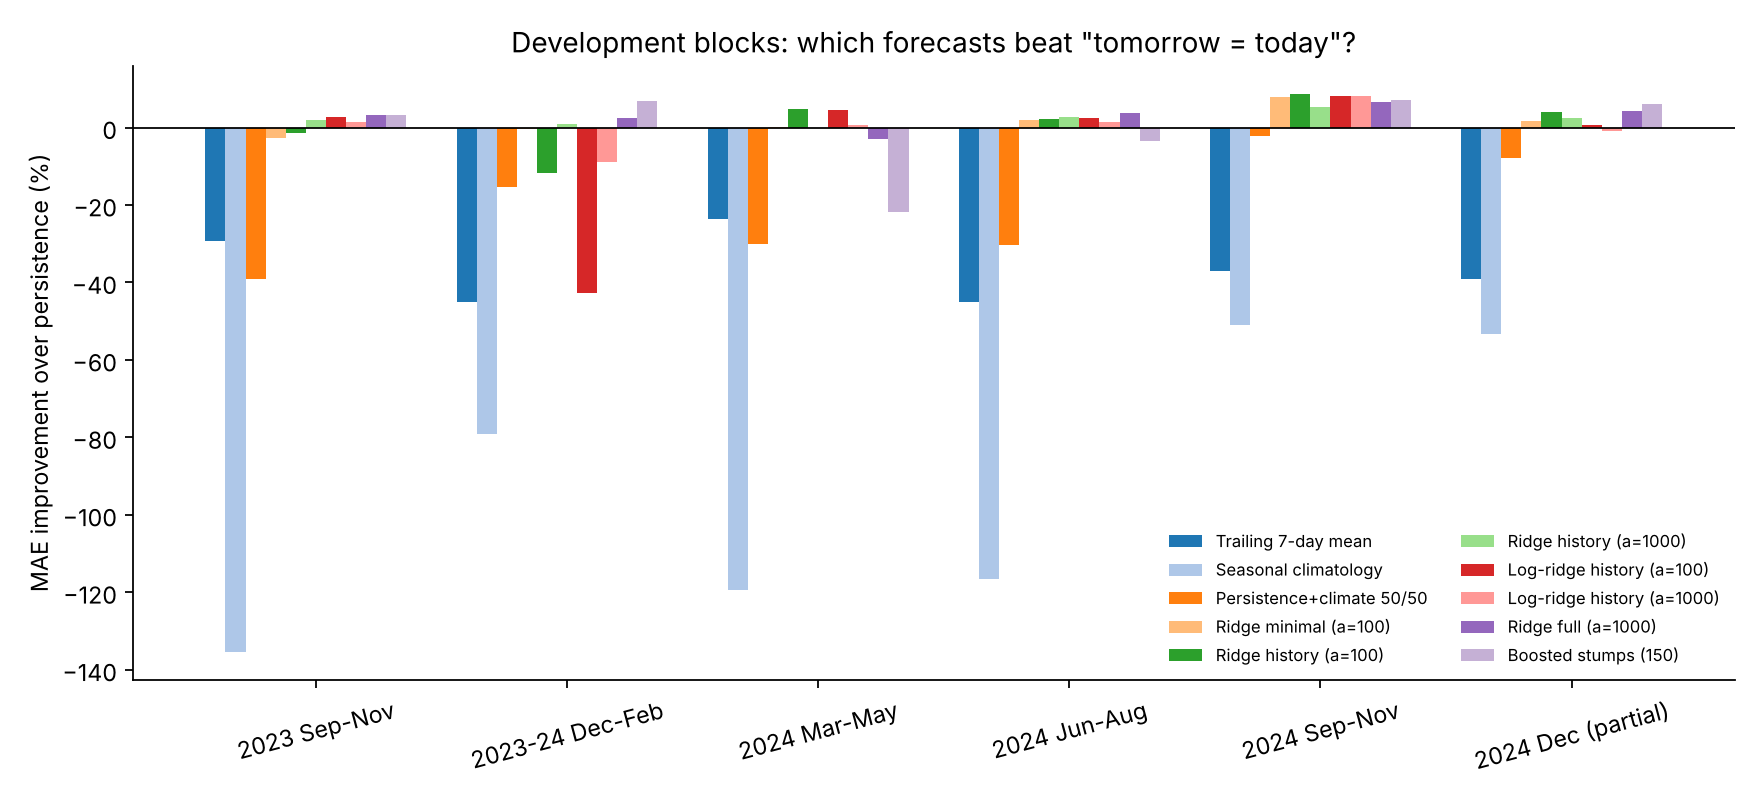

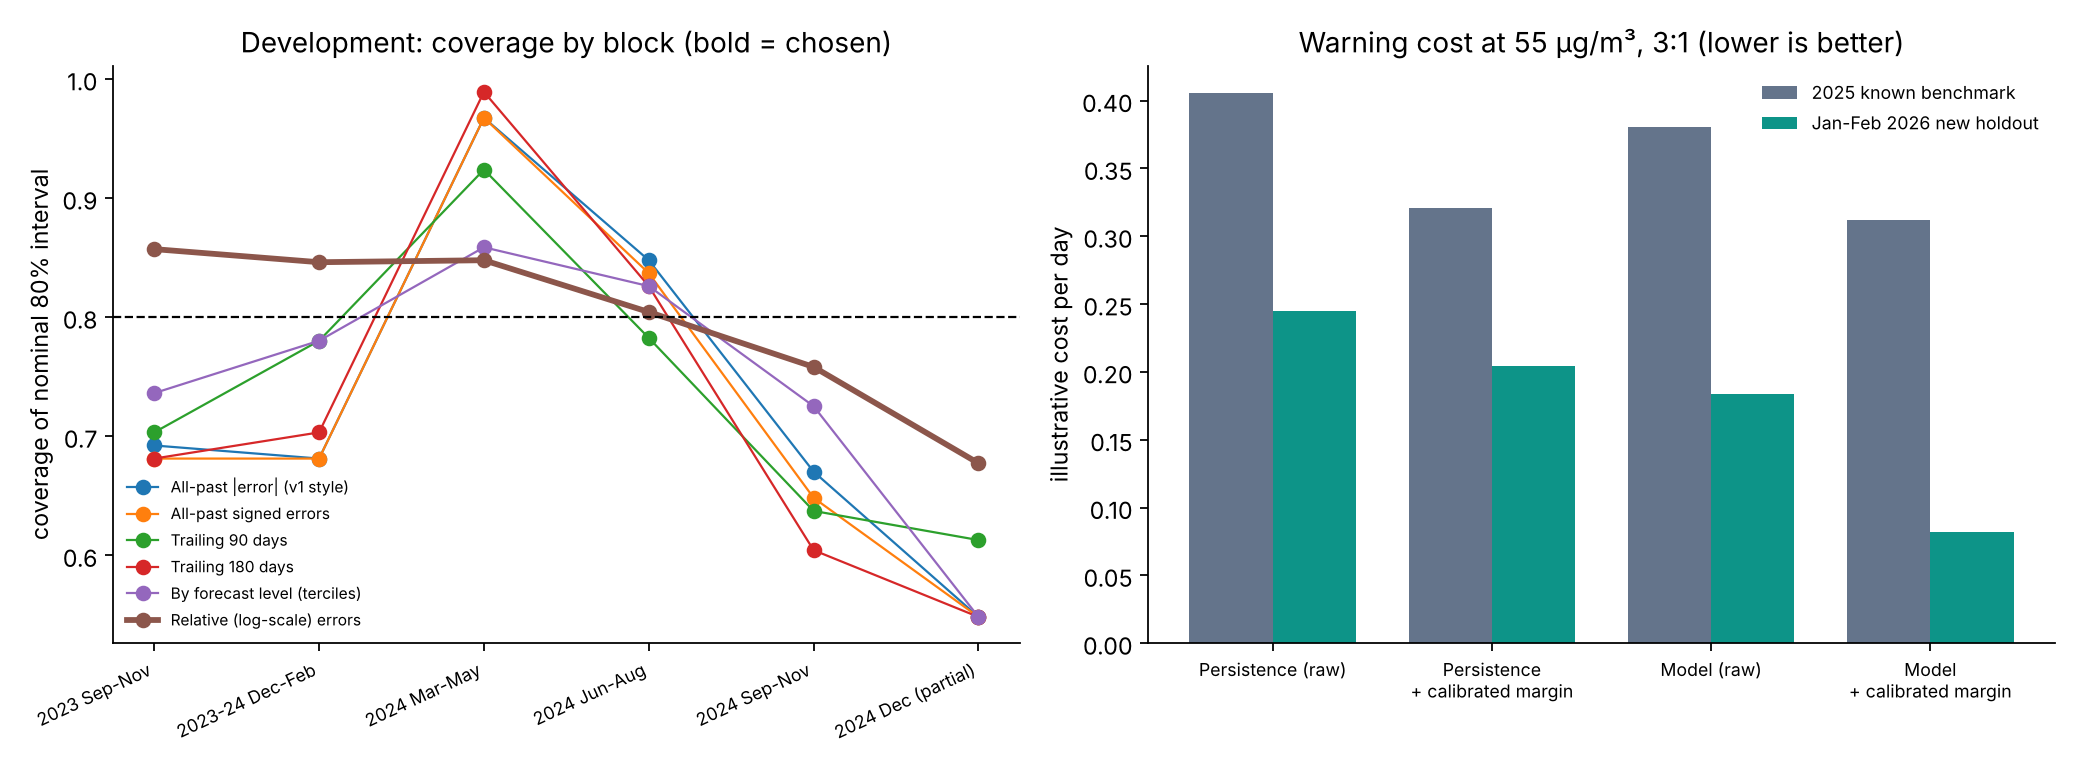

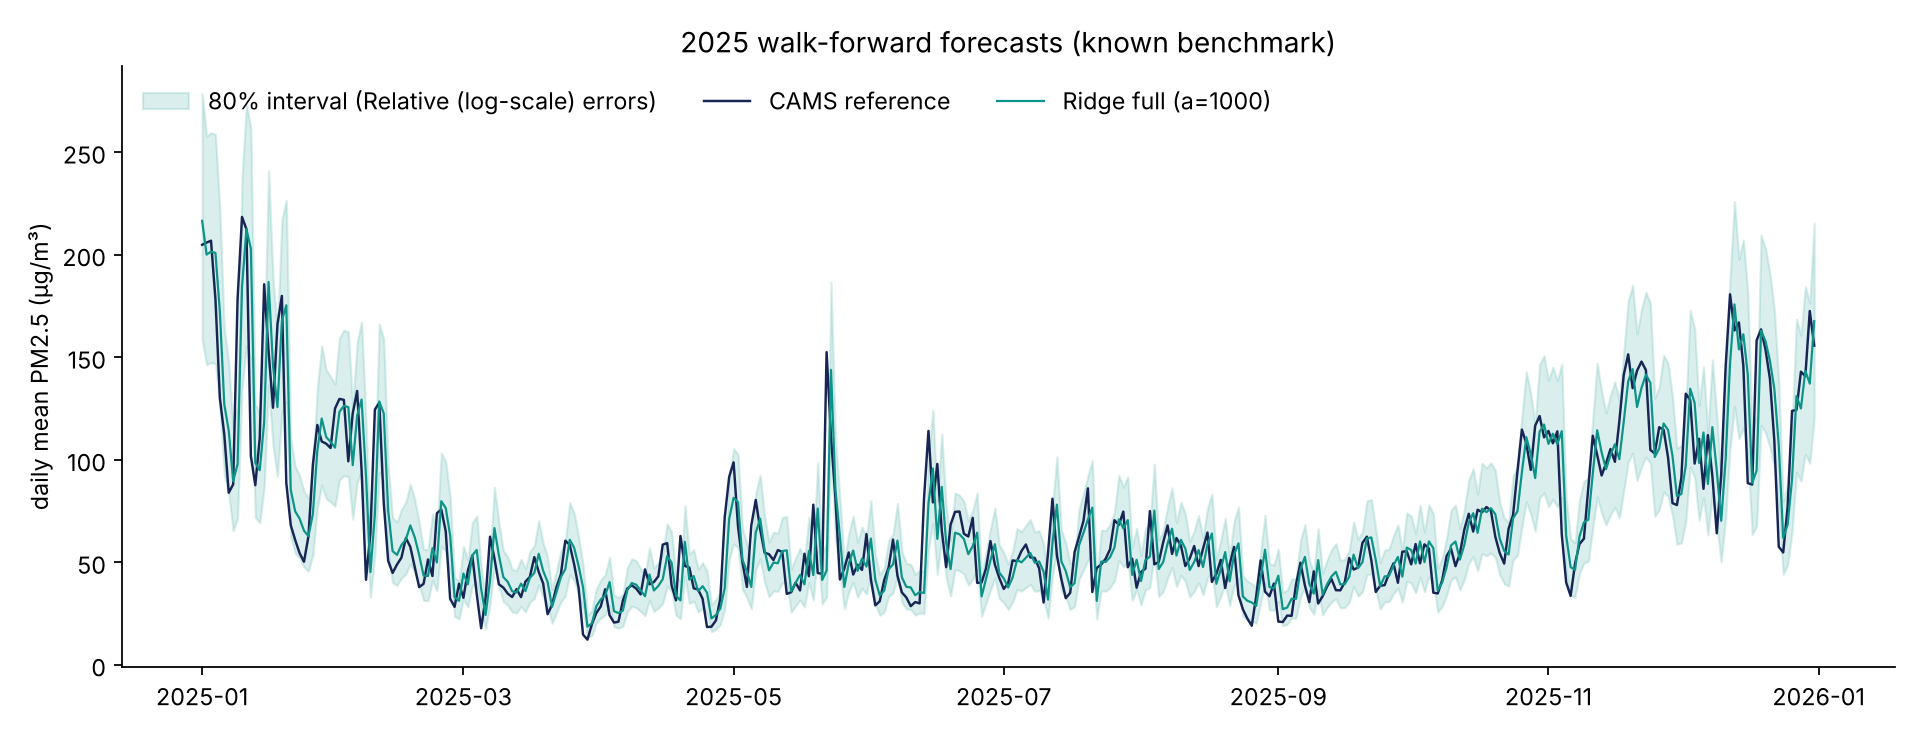

In [11]:
from IPython.display import Image, display
for f in ['model_comparison','decision_comparison','forecast']: display(Image(f'results/{f}.png'))

## 5. Decision dashboard
Builds the same offline dashboard shipped as `SmogWindow_dashboard.html` and shows it inline (in Colab, or download it from the file panel). Try origin 2025-05-21 and *Jump to a missed spike*.

In [12]:
import build_dashboard, html as _h
from IPython.display import HTML, display
build_dashboard.build()
page = open('SmogWindow_dashboard.html', encoding='utf-8').read()
display(HTML('<iframe srcdoc="' + _h.escape(page, quote=True) + '" width="100%" height="1500" style="border:1px solid #ccc"></iframe>'))

/usr/local/lib/python3.12/dist-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


## 6. Issue one forecast from a history file (the operational workflow)

In [13]:
!python plan_live.py --asof 2025-05-21

SmogWindow planning summary - Lahore, PM2.5 (modeled)
Forecast origin: 2025-05-21   Forecast for: 2025-05-22
Forecast daily mean: 46 ug/m3   80% range: 33-60 ug/m3   (method: Relative (log-scale) errors)
Persistence ('tomorrow = today'): 44 ug/m3
Assumptions: planning threshold 55 ug/m3; a missed high day is treated as 3x as costly as a false alarm (illustrative, not a regulation).
Planning flag (model + margin): NO flag at these settings (this is not a safety clearance)
Calibrated-persistence flag: NO
Data checks: 14-day window complete.
Limits:
- Values are CAMS atmospheric-model estimates, not measurements at a school or a monitor.
- A planning flag means "prepare an alternative"; no flag does NOT mean outdoor activity is safe.
- Check official air-quality guidance and current local readings before deciding.
- Research prototype: not medical advice, not a safety clearance, not validated by any school.


## Sources, limits, authorship
- Lahore dataset: Kulkarni & Tawade, Zenodo [10.5281/zenodo.18673725](https://doi.org/10.5281/zenodo.18673725) (CAMS via [Open-Meteo](https://open-meteo.com/en/docs/air-quality-api)); not ground truth.
- Limits: 2025 was examined by an earlier version (known benchmark, not tuned on); the 2026 holdout is only 49 winter days; thresholds and cost ratios are illustrative; `validate_ground.py` needs real monitor data that we have not obtained; the Open-Meteo fetch helper is untested live.
- AI assistance: OpenAI ChatGPT/Codex and Anthropic Claude. Review and be able to explain everything; do not claim unaided authorship.